# Identifiability of the ISI decomposition

Synthetic recovery of the time-varying signal importance $w(t)$ and the response functions $f$, plus a negative control testing whether ISI fabricates time variation.

Panels: (a) importance recovery, (b) response functions, (c) negative control, (d) filter recovery versus process noise, (e) importance recovery over the same range.

Run from a directory containing `ISI.py`.

## Setup

Constants, and a subclass that makes the ridge step robust to the scikit-learn version (`coef_` is `(1, n_features)` in older releases and `(n_features,)` in recent ones). `ISI.py` itself is used unmodified.

In [1]:
import contextlib
import io

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

import ISI

matplotlib.rcParams["pdf.fonttype"] = 42

SIGNAL_NAMES = ["SR", "WT", "DL", "GSI"]
SIGNAL_COLORS = ["red", "blue", "orange", "green"]
N_SIGNALS = len(SIGNAL_NAMES)

RANDOM_SEED = 3
N_DAYS = 735
SAMPLING_DAYS = np.arange(20, N_DAYS, 15)[:48].astype(float)
WINDOW_SIZE = 5                      # kernel length, held at its true value throughout
OBSERVATION_NOISE_SD = 0.2
OBSERVATION_NOISE_CORRELATION = 0.2
RIDGE_ALPHA = 1.0                    # as in the published analysis
PROCESS_NOISE_GRID = [0.05, 0.1, 0.25, 0.5, 1, 2, 4, 8]
CROSS_VALIDATION_FOLDS = [(0, 1, 2), (2, 0, 1), (1, 2, 0)]


class EMAlgorithmCompat(ISI.EMAlgorithm):
    """ISI.EMAlgorithm with a scikit-learn-version-robust ridge step."""

    def _fit_ridge(self, X, Y, alpha):
        coefficients = np.asarray(Ridge(alpha=alpha).fit(X, Y).coef_)
        return coefficients[0] if coefficients.ndim == 2 else coefficients


@contextlib.contextmanager
def suppressed_stdout():
    """Silence the per-iteration messages printed inside ISI.EMAlgorithm.fit."""
    with contextlib.redirect_stdout(io.StringIO()):
        yield

## Synthetic data

Four input signals, unit-norm response functions with distinct shapes, and importance trajectories that are either time-varying or constant. Trajectory amplitudes are balanced so that every signal contributes comparably to the output.

In [2]:
def generate_daily_signals():
    """Four daily input signals with seasonal structure, standardized as in the pipeline."""
    rng = np.random.default_rng(RANDOM_SEED)
    day = np.arange(N_DAYS, dtype=float)
    phase = 2 * np.pi * day / 365.0

    signals = pd.DataFrame({
        "SR": 14 + 6 * np.sin(phase - 1.3) + rng.normal(0, 9.0, N_DAYS),
        "WT": 18 + 8 * np.sin(phase - 1.8) + np.cumsum(rng.normal(0, 0.6, N_DAYS)) * 0.5,
        "DL": 12 + 2 * np.sin(phase - 1.2),
        "GSI": (6 + 3 * np.sin(2 * phase - 0.3) + 2 * np.sin(4 * phase + 0.7)
                + np.sin(6 * phase)),
    })
    return pd.DataFrame(StandardScaler().fit_transform(signals), columns=SIGNAL_NAMES)


def build_window_matrix(daily_signals, window_size):
    """Sliding-window design matrix; column (i*window + j) is signal i, j days into the window.

    The last column of each signal block is the sampling day itself, matching the layout
    used by the main analysis.
    """
    values = daily_signals.to_numpy()
    return np.array([values[int(d) - window_size + 1:int(d) + 1].T.reshape(-1)
                     for d in SAMPLING_DAYS])


def make_true_response_functions(window_size):
    """Unit-norm filters with distinct shapes, including a differentiator for GSI."""
    lag = np.arange(window_size)[::-1].astype(float)     # days before the sampling day
    shapes = np.array([
        np.exp(-lag / 1.0),                              # SR : fast decay
        np.exp(-lag / 3.0),                              # WT : slow decay
        np.exp(-((lag - window_size / 2) ** 2) / 1.28),  # DL : delayed peak
        np.linspace(-1.0, 1.0, window_size),             # GSI: differentiator
    ])
    return shapes / np.linalg.norm(shapes, axis=1, keepdims=True)


def make_true_importance_shapes(time_varying=True):
    """Dimensionless importance trajectories, before balancing across signals."""
    phase = 2 * np.pi * SAMPLING_DAYS / 365.0
    if not time_varying:
        return np.tile([1.2, 0.9, 0.7, 1.0], (len(SAMPLING_DAYS), 1))
    return np.column_stack([
        1.2 + 0.9 * np.sin(2 * phase - 0.5),                 # two peaks per year
        0.9 + 0.7 * np.sin(phase - 2.5),                     # one slow cycle
        1.5 - 1.6 * SAMPLING_DAYS / SAMPLING_DAYS.max(),     # monotonic decline
        1.0 + 0.9 * np.sin(phase - 1.0),                     # one cycle, shifted phase
    ])


def compute_processed_signals(window_matrix, response_functions):
    """g_i(t) = (f_i * x_i)(t) for every signal."""
    window_size = response_functions.shape[1]
    return np.column_stack([
        window_matrix[:, i * window_size:(i + 1) * window_size] @ response_functions[i]
        for i in range(N_SIGNALS)])


def build_dataset(time_varying=True):
    """Synthetic dataset with known response functions and known importance."""
    daily_signals = generate_daily_signals()
    window_matrix = build_window_matrix(daily_signals, WINDOW_SIZE)
    response_functions = make_true_response_functions(WINDOW_SIZE)
    processed = compute_processed_signals(window_matrix, response_functions)

    # balance so that every signal contributes comparably to the output
    importance = make_true_importance_shapes(time_varying) / processed.std(axis=0)

    noise_free_output = np.sum(importance * processed, axis=1)
    output_scaling = 1.0 / noise_free_output.std()          # put the output on unit SD
    noise_free_output *= output_scaling

    covariance = np.full((3, 3), OBSERVATION_NOISE_CORRELATION * OBSERVATION_NOISE_SD ** 2)
    np.fill_diagonal(covariance, OBSERVATION_NOISE_SD ** 2)
    noise = np.random.default_rng(RANDOM_SEED + 7).multivariate_normal(
        np.zeros(3), covariance, size=len(noise_free_output))

    return {
        "daily_signals": daily_signals,
        "noise_free_output": noise_free_output,
        "window_matrix": window_matrix,
        "replicate_outputs": [noise_free_output + noise[:, r] for r in range(3)],
        "true_response_functions": response_functions,
        "true_importance": importance * output_scaling,
    }


time_varying_dataset = build_dataset(time_varying=True)
fixed_weight_dataset = build_dataset(time_varying=False)

## Input and output data

The four standardized input signals $x_i(t)$, sampled daily, and the output $y_t$ at the 48 sampling points: the noise-free response generated by the model together with the three replicate observations.

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


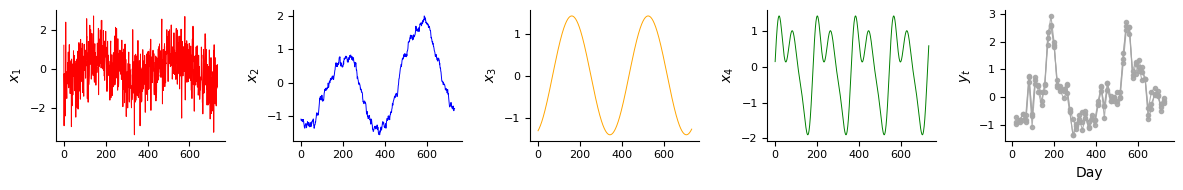

In [3]:
def plot_input_and_output(dataset):
    """Show the four input signals x_i(t) and the observed output y_t."""
    daily_signals = dataset["daily_signals"]
    day = np.arange(N_DAYS)

    figure, axes = plt.subplots(1, 5, figsize=(12.0, 2.0), sharex=True)
    for axis, name, color,id in zip(axes, SIGNAL_NAMES, SIGNAL_COLORS, [1,2,3,4,5]):
        axis.plot(day, daily_signals[name], color=color, linewidth=0.7)
        axis.set_ylabel(f"$x_{{{id}}}$", fontsize=10)

    output_axis = axes[-1]
    for replicate, output in enumerate(dataset["replicate_outputs"]):
        output_axis.plot(SAMPLING_DAYS, output, "o-", color="0.65", markersize=3,
                         linewidth=0.8, alpha=0.9)

    output_axis.set_ylabel("$y_t$", fontsize=10)
    output_axis.set_xlabel("Day", fontsize=10)
    output_axis.legend(frameon=False, fontsize=8, ncol=2)

    for axis in axes:
        axis.tick_params(labelsize=8)
        axis.spines[["top", "right"]].set_visible(False)
    figure.tight_layout()
    plt.show()


plot_input_and_output(time_varying_dataset)

In [4]:
print("Original environmental signals")
print(time_varying_dataset["daily_signals"].shape)

print("\nDesign matrix  (48 sampling points x [5 window taps * 4 signals])")
print(time_varying_dataset["window_matrix"].shape)

print("\nResponse functions  (4 signals x 5 taps)")
print(time_varying_dataset["true_response_functions"].shape)

print("\nOutput")
print(time_varying_dataset["noise_free_output"].shape)

# the true filters are built with unit norm, which is why no gauge fixing is
# needed on the ground-truth side
print("\nSquared norm of each true response function")
print(np.sum(time_varying_dataset["true_response_functions"] ** 2, axis=1))


Original environmental signals
(735, 4)

Design matrix  (48 sampling points x [5 window taps * 4 signals])
(48, 20)

Response functions  (4 signals x 5 taps)
(4, 5)

Output
(48,)

Squared norm of each true response function
[1. 1. 1. 1.]


## Gauge fixing

The model depends only on the product $w_i(t)\,(f_i * x_i)(t)$, so $(w_i, f_i)$ and
$(c_i w_i,\; f_i/c_i)$ are indistinguishable for any constant $c_i \neq 0$. We remove the
freedom by normalizing the **importance**, not the filter:

$$\mathrm{RMS}_t(w_i) \;=\; \sqrt{\tfrac{1}{T}\textstyle\sum_t w_i(t)^2} \;=\; 1 .$$

Each $w_i(t)$ then reads as a dimensionless modulation about its own typical level, while
$f_i$ keeps the typical amplitude of that signal's contribution — so a weak, nearly flat
filter still looks weak, instead of being blown up to the size of a strong one.

The divisor is one constant per signal, so this is an exact reparameterization: waveform
shapes, the model fit and every correlation-based result are unchanged. (A sum-to-one
constraint on $w$ would divide by the time-dependent $\sum_j w_j(t)$; that is *not* a gauge
transformation and would distort both the trajectories and the fit.)

RMS is used rather than the mean, which is unstable for a trajectory crossing zero, or the
standard deviation, which vanishes for a fixed-weight ground truth.

The residual freedom is the joint sign flip $(f_i, w_i) \to (-f_i, -w_i)$, so filter
similarity is reported as $|\cos|$ and must be read against the chance level below.

In [5]:
def apply_gauge_fixing(response_function, importance, window_size):
    """Rescale (f_i, w_i) to the canonical gauge RMS_t(w_i) = 1.

    The divisor is one constant per signal, so this is an exact reparameterization:
    waveform shapes, predictions and every correlation-based result are unchanged, and
    no re-estimation is required.
    """
    filters = np.asarray(response_function, float).reshape(N_SIGNALS, window_size).copy()
    rescaled = np.asarray(importance, float).copy()
    for i in range(N_SIGNALS):
        typical_importance = np.sqrt(np.mean(rescaled[:, i] ** 2))
        filters[i] *= typical_importance
        rescaled[:, i] /= typical_importance
    return filters, rescaled


def absolute_cosine_similarity(first_filter, second_filter):
    """|cos| between two response functions.

    The filters are no longer unit vectors under this gauge, so the norms are divided out
    explicitly. The absolute value reflects the unidentifiable joint sign.
    """
    return float(abs(np.dot(first_filter, second_filter))
                 / (np.linalg.norm(first_filter) * np.linalg.norm(second_filter)))


def simulate_chance_level_for_cosine(window_size, n_draws=200_000):
    """95th percentile of |cos| between random directions.

    The symmetry (f_i, w_i) -> (-f_i, -w_i) leaves the sign of a filter unidentifiable,
    so filter similarity is reported as |cos|. Its floor is therefore chance agreement
    between random directions, not zero.
    """
    rng = np.random.default_rng(0)
    a, b = rng.normal(size=(n_draws, window_size)), rng.normal(size=(n_draws, window_size))
    cosine = np.abs(np.sum(a * b, axis=1)) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1))
    return float(np.percentile(cosine, 95))

In [6]:
print("before")
print(np.mean(time_varying_dataset["true_importance"][:,0]**2))

# the ground truth must be expressed in the same gauge before anything is compared
time_varying_dataset["true_response_functions"], time_varying_dataset["true_importance"] = apply_gauge_fixing(
    time_varying_dataset["true_response_functions"],
    time_varying_dataset["true_importance"], WINDOW_SIZE)

print("after")
print(np.mean(time_varying_dataset["true_importance"][:,0]**2))


before
0.17329586314556647
after
1.0


## Fitting

The pipeline of the main analysis: cross-validate the process noise across replicate groups, then fit on all replicates and report in the canonical gauge.

In [7]:
def fit_isi(window_matrix, outputs, process_noise_var, max_iter=1000,
            noise_sd=OBSERVATION_NOISE_SD):
    """Fit the ISI model and return the estimate in the canonical gauge."""
    em = EMAlgorithmCompat(
        window_size=WINDOW_SIZE, process_noise_var=process_noise_var,
        observe_noise_var=noise_sd ** 2,
        observe_noise_cov=OBSERVATION_NOISE_CORRELATION * noise_sd ** 2,
        alpha=RIDGE_ALPHA)
    with suppressed_stdout():
        importance, _, response_function, _, _ = em.fit(
            X_list=[window_matrix] * len(outputs), Y_list=outputs,
            times=SAMPLING_DAYS, n_signals=N_SIGNALS, max_iter=max_iter)
    return em, importance, response_function


def compute_held_out_rss(dataset, process_noise_var, max_iter=1000):
    """Mean held-out RSS over three folds: train on two replicates, test on the third."""
    window_matrix, outputs = dataset["window_matrix"], dataset["replicate_outputs"]
    scores = []
    for train_a, train_b, test in CROSS_VALIDATION_FOLDS:
        em, importance, response_function = fit_isi(
            window_matrix, [outputs[train_a], outputs[train_b]], process_noise_var, max_iter,
            noise_sd=dataset.get("noise_sd", OBSERVATION_NOISE_SD))
        rss, _ = em.test(X_list=[window_matrix], Y_list=[outputs[test]],
                         x_smooth=importance, coef=response_function)
        scores.append(rss)
    return float(np.mean(scores))


def select_process_noise(dataset):
    """Pick the process noise minimizing held-out error."""
    scores = {q: compute_held_out_rss(dataset, q, max_iter=200) for q in PROCESS_NOISE_GRID}
    return min(scores, key=scores.get), scores


def estimate_in_canonical_gauge(dataset, process_noise_var):
    """Fit on all replicates and return the estimate in the canonical gauge."""
    _, importance, response_function = fit_isi(
        dataset["window_matrix"], dataset["replicate_outputs"], process_noise_var,
        noise_sd=dataset.get("noise_sd", OBSERVATION_NOISE_SD))
    return apply_gauge_fixing(response_function, importance, WINDOW_SIZE)

## Analyses

Recovery from time-varying data, the fixed-weight negative control, and a sweep of the process noise. Setting the process noise to ~0 freezes the weights, which gives the nested fixed-weight model for the held-out comparison.

In [8]:
def temporal_coefficient_of_variation(importance):
    return importance.std(axis=0) / np.abs(importance.mean(axis=0))


selected_process_noise, _ = select_process_noise(time_varying_dataset)
estimated_filters, estimated_importance = \
    estimate_in_canonical_gauge(time_varying_dataset, selected_process_noise)


# the ground truth must be expressed in the same gauge before anything is compared
true_filters = time_varying_dataset["true_response_functions"]
true_importance = time_varying_dataset["true_importance"]


filter_amplitude_ratio = np.array([
    np.linalg.norm(estimated_filters[i]) / np.linalg.norm(true_filters[i])
    for i in range(N_SIGNALS)])

importance_correlation = np.array([
    np.corrcoef(true_importance[:, i], estimated_importance[:, i])[0, 1] for i in range(N_SIGNALS)])

fixed_weight_process_noise, _ = select_process_noise(fixed_weight_dataset)
_, fixed_weight_estimate = estimate_in_canonical_gauge(fixed_weight_dataset, fixed_weight_process_noise)

variability_time_varying = temporal_coefficient_of_variation(estimated_importance)
variability_fixed_weight = temporal_coefficient_of_variation(fixed_weight_estimate)

# nested comparison: a process noise of ~0 freezes the weights, giving a fixed-weight model
held_out = {
    "time-varying truth": (compute_held_out_rss(time_varying_dataset, selected_process_noise),
                           compute_held_out_rss(time_varying_dataset, 1e-6)),
    "fixed-weight truth": (compute_held_out_rss(fixed_weight_dataset, fixed_weight_process_noise),
                           compute_held_out_rss(fixed_weight_dataset, 1e-6)),
}
held_out_gain = {name: 100 * (1 - flexible / frozen) for name, (flexible, frozen) in held_out.items()}

# sweep: how recovery depends on how freely w(t) may move
sweep_cosine, sweep_correlation = [], []
for process_noise in PROCESS_NOISE_GRID:
    estimate_f, estimate_w = estimate_in_canonical_gauge(time_varying_dataset, process_noise)
    sweep_cosine.append([absolute_cosine_similarity(true_filters[i], estimate_f[i])
                         for i in range(N_SIGNALS)])
    sweep_correlation.append([np.corrcoef(true_importance[:, i], estimate_w[:, i])[0, 1]
                              for i in range(N_SIGNALS)])
sweep_cosine, sweep_correlation = np.array(sweep_cosine), np.array(sweep_correlation)
chance_level = simulate_chance_level_for_cosine(WINDOW_SIZE)

## Figure

correlation of w(t)    : [0.743 0.839 0.98  0.794]
|f| ratio est/true     : [0.971 1.25  1.185 0.762]


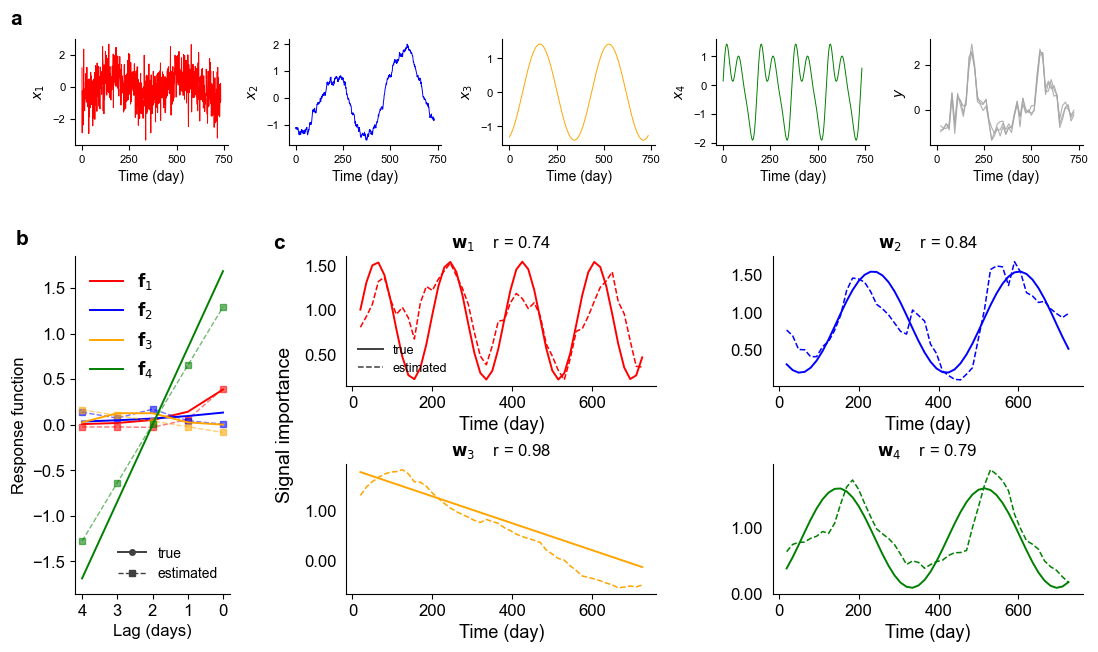

In [57]:
# -------------------------------------------------------------------
# Visualization of ISI recovery
# Layout: a  inputs x_1..x_4 and output y_t
#         b  response functions | c  signal importance (2x2)
# -------------------------------------------------------------------
from matplotlib.ticker import FormatStrFormatter
from matplotlib.lines import Line2D

if "Arial" in {f.name for f in matplotlib.font_manager.fontManager.ttflist}:
    matplotlib.rcParams["font.family"] = "Arial"
matplotlib.rcParams["pdf.fonttype"] = 42

dataset       = time_varying_dataset
daily_signals = dataset["daily_signals"]
day           = np.arange(N_DAYS)

fig   = plt.figure(figsize=(13, 7.2))
outer = fig.add_gridspec(2, 1, height_ratios=[1.0, 3.2], hspace=0.5)

# ---- a: input signals and observed output --------------------------
top    = outer[0].subgridspec(1, 5, wspace=0.40)
ax_in  = [fig.add_subplot(top[0])]
ax_in += [fig.add_subplot(top[c], sharex=ax_in[0]) for c in range(1, 5)]

for axis, name, color, sid in zip(ax_in, SIGNAL_NAMES, SIGNAL_COLORS, [1, 2, 3, 4]):
    axis.plot(day, daily_signals[name], color=color, linewidth=0.7)
    axis.set_ylabel(rf"$x_{{{sid}}}$", fontsize=10)

ax_out = ax_in[-1]
for output in dataset["replicate_outputs"]:
    ax_out.plot(SAMPLING_DAYS, output, "-", color="0.65", markersize=3,
                linewidth=0.8, alpha=0.9)
ax_out.set_ylabel("$y$", fontsize=10)

for axis in ax_in:
    axis.set_xlabel("Time (day)", fontsize=10)
    axis.tick_params(labelsize=8)
    axis.spines[["top", "right"]].set_visible(False)

# ---- b | c ---------------------------------------------------------
low  = outer[1].subgridspec(2, 3, width_ratios=[1, 2, 2], wspace=0.45, hspace=0.6)
ax_a = fig.add_subplot(low[:, 0])

ax_b_frame = fig.add_subplot(low[:, 1:])
ax_b_frame.set_frame_on(False)
ax_b_frame.set_xticks([]); ax_b_frame.set_yticks([])
ax_b_frame.set_ylabel("Signal importance", fontsize=14,  labelpad=38)

ax_b = [fig.add_subplot(low[r, c + 1]) for r in range(2) for c in range(2)]

labels_w = [r"$\mathbf{w}_{1}$", r"$\mathbf{w}_{2}$",
            r"$\mathbf{w}_{3}$", r"$\mathbf{w}_{4}$"]
labels_f = [r"$\mathbf{f}_{1}$", r"$\mathbf{f}_{2}$",
            r"$\mathbf{f}_{3}$", r"$\mathbf{f}_{4}$"]
colors = SIGNAL_COLORS

style_handles = [Line2D([], [], color="0.25", linestyle="-",  marker="o",
                        markersize=4, linewidth=1.4, label="true"),
                 Line2D([], [], color="0.25", linestyle="--", marker="s",
                        markersize=4, linewidth=1.0, label="estimated")]

for i, (col, lab) in enumerate(zip(colors, labels_f)):
    ax_a.plot(true_filters[i], "-", color=col, linewidth=1.4, label=lab)
    ax_a.plot(estimated_filters[i], "s--", color=col, linewidth=1.0,
              markersize=4, alpha=0.55)

ax_a.set_ylabel("Response function", fontsize=12)
ax_a.set_xlabel("Lag (days)", fontsize=12)
ax_a.set_xticks(range(WINDOW_SIZE))
ax_a.set_xticklabels(range(WINDOW_SIZE - 1, -1, -1), fontsize=12)
ax_a.tick_params(axis="y", labelsize=12)
ax_a.spines[["top", "right"]].set_visible(False)

leg_f = ax_a.legend(loc="upper left", fontsize=12, frameon=False)
ax_a.add_artist(leg_f)
ax_a.legend(handles=style_handles, loc="lower right", fontsize=10, frameon=False)

for i, (col, lab) in enumerate(zip(colors, labels_w)):
    ax_b[i].plot(SAMPLING_DAYS, true_importance[:, i], color=col,
                 linestyle="-", linewidth=1.4)
    ax_b[i].plot(SAMPLING_DAYS, estimated_importance[:, i], color=col,
                 linestyle="--", linewidth=1.1)
    ax_b[i].set_title(f"{lab}    r = {importance_correlation[i]:.2f}", fontsize=12)
    ax_b[i].spines[["top", "right"]].set_visible(False)
    ax_b[i].tick_params(left=False, bottom=False, axis="y", labelsize=12)
    ax_b[i].set_xticks([0, 200, 400, 600])
    ax_b[i].set_xticklabels(["0", "200", "400", "600"], fontsize=12)
    ax_b[i].set_xlabel("Time (day)", fontsize=13)
    ax_b[i].yaxis.set_major_formatter(FormatStrFormatter("%1.2f"))

ax_b[0].legend(handles=[Line2D([], [], color="0.25", linestyle="-",  linewidth=1.4, label="true"),
                        Line2D([], [], color="0.25", linestyle="--", linewidth=1.1, label="estimated")],
               loc="best", fontsize=9, frameon=False)

# ---- panel labels --------------------------------------------------
def panel_label(axis, text, dx=-0.12, dy=1.06):
    axis.text(dx, dy, text, transform=axis.transAxes,
              fontsize=15, fontweight="bold", va="bottom", ha="right",
              clip_on=False)

panel_label(ax_in[0], "a", dx=-0.35, dy=1.10)
panel_label(ax_a,     "b", dx=-0.30, dy=1.02)
panel_label(ax_b[0],  "c", dx=-0.20 , dy=1.02)

fig.savefig("ReviseFigure/", bbox_inches="tight")
#fig.savefig("SupplementaryFigure_Identifiability.png", dpi=200, bbox_inches="tight")
#plt.show()

print("correlation of w(t)    :", np.round(importance_correlation, 3))
print("|f| ratio est/true     :", np.round(filter_amplitude_ratio, 3))

In [52]:
len(dataset["replicate_outputs"])
#dataset["replicate_outputs"][0].shape

3

/var/folders/nh/xsx_6tbx0xg13fwlq2m_8yn40000gn/T/ipykernel_53039/226946739.py:50: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  ax_b[i].plot(SAMPLING_DAYS, estimated_importance[:, i], "k--", color=col, linewidth=1.1)
/var/folders/nh/xsx_6tbx0xg13fwlq2m_8yn40000gn/T/ipykernel_53039/226946739.py:50: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  ax_b[i].plot(SAMPLING_DAYS, estimated_importance[:, i], "k--", color=col, linewidth=1.1)
/var/folders/nh/xsx_6tbx0xg13fwlq2m_8yn40000gn/T/ipykernel_53039/226946739.py:50: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  ax_b[i].plot(SAMPLING_DAYS, estimated_importance[:, i], "k--", color=col, linewidth=1.1)
/var/fo

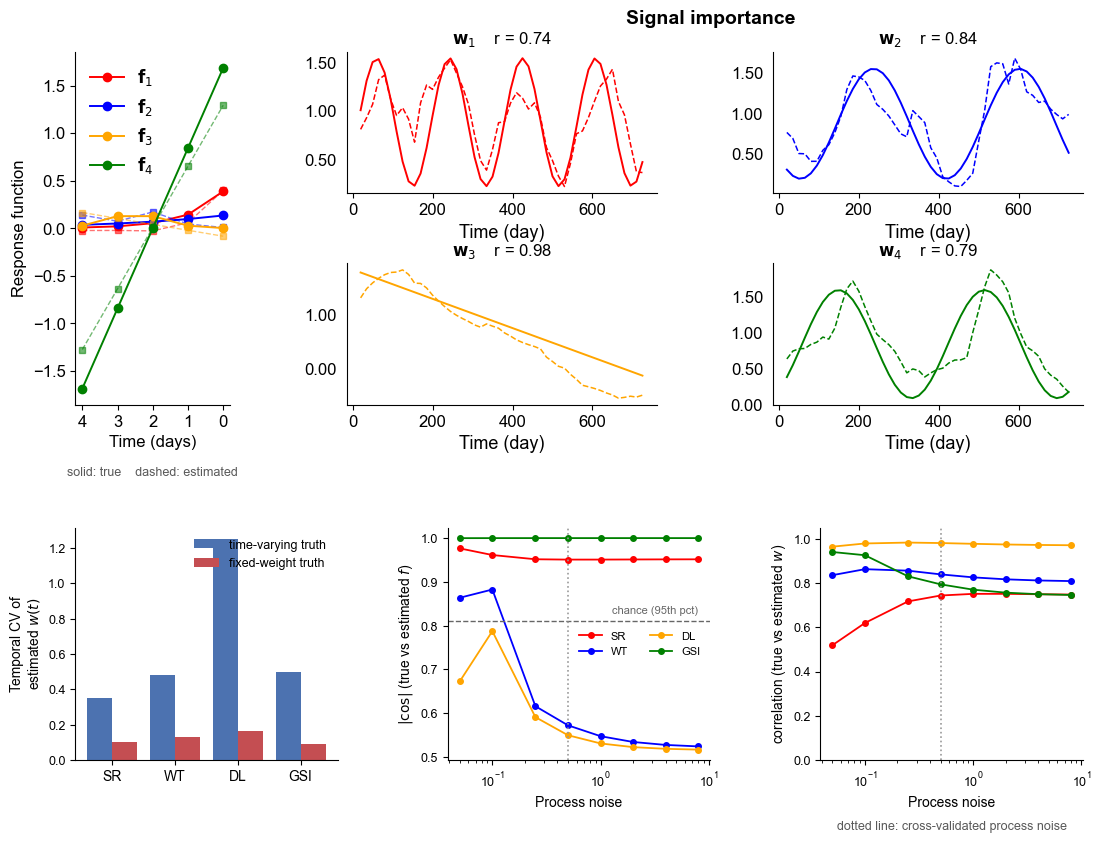

selected process noise : 0.5
correlation of w(t)    : [0.743 0.839 0.98  0.794]
|f| ratio est/true     : [0.971 1.25  1.185 0.762]
|cos| of f             : [0.951 0.572 0.55  1.   ]
temporal CV, time-varying / fixed-weight : [0.353 0.484 1.253 0.498] [0.104 0.133 0.168 0.091]
held-out gain (%)      : {'time-varying truth': 86.6, 'fixed-weight truth': 5.7}


In [15]:
# -------------------------------------------------------------------
# Visualization of ISI recovery
# Layout: A (response functions) | B (signal importance, 2x2 panels)
#         C, D, E below: negative control and process-noise sweeps
# -------------------------------------------------------------------
from matplotlib.ticker import FormatStrFormatter

if "Arial" in {f.name for f in matplotlib.font_manager.fontManager.ttflist}:
    matplotlib.rcParams["font.family"] = "Arial"
matplotlib.rcParams["pdf.fonttype"] = 42

fig = plt.figure(figsize=(13, 9.2))
outer = fig.add_gridspec(2, 1, height_ratios=[4.7, 3.1], hspace=0.42)
top = outer[0].subgridspec(2, 3, width_ratios=[1, 2, 2], wspace=0.45, hspace=0.5)
bottom = outer[1].subgridspec(1, 3, wspace=0.42)

ax_a = fig.add_subplot(top[:, 0])                        # A: full-height left panel
ax_b = [fig.add_subplot(top[r, c + 1])                   # B: 2x2 right panels
        for r in range(2) for c in range(2)]

labels_w = [r"$\mathbf{w}_{1}$", r"$\mathbf{w}_{2}$",
            r"$\mathbf{w}_{3}$", r"$\mathbf{w}_{4}$"]
labels_f = [r"$\mathbf{f}_{1}$", r"$\mathbf{f}_{2}$",
            r"$\mathbf{f}_{3}$", r"$\mathbf{f}_{4}$"]
colors = SIGNAL_COLORS

# -------------------------------------------------------------------
# Panel A: response functions
# -------------------------------------------------------------------
for i, (col, lab) in enumerate(zip(colors, labels_f)):
    ax_a.plot(true_filters[i], "o-", color=col, linewidth=1.4, label=lab)
    ax_a.plot(estimated_filters[i], "s--", color=col, linewidth=1.0,
              markersize=4, alpha=0.55)

ax_a.set_ylabel("Response function", fontsize=12)
ax_a.set_xlabel("Time (days)", fontsize=12)
ax_a.set_xticks(range(WINDOW_SIZE))
ax_a.set_xticklabels(range(WINDOW_SIZE - 1, -1, -1), fontsize=12)
ax_a.tick_params(axis="y", labelsize=12)
ax_a.legend(loc="best", fontsize=12, frameon=False)
ax_a.spines[["top", "right"]].set_visible(False)
ax_a.text(0.5, -0.20, "solid: true    dashed: estimated", transform=ax_a.transAxes,
          ha="center", fontsize=9, color="0.35")

# -------------------------------------------------------------------
# Panel B: time-varying signal importance (2x2)
# -------------------------------------------------------------------
for i, (col, lab) in enumerate(zip(colors, labels_w)):
    ax_b[i].plot(SAMPLING_DAYS, true_importance[:, i], color=col, linewidth=1.4, label=lab)
    ax_b[i].plot(SAMPLING_DAYS, estimated_importance[:, i], "k--", color=col, linewidth=1.1)
    ax_b[i].set_title(f"{lab}    r = {importance_correlation[i]:.2f}", fontsize=12)
    ax_b[i].spines[["top", "right"]].set_visible(False)
    ax_b[i].tick_params(left=False, bottom=False, axis="y", labelsize=12)
    ax_b[i].set_xticks([0, 200, 400, 600])
    ax_b[i].set_xticklabels(["0", "200", "400", "600"], fontsize=12)
    ax_b[i].set_xlabel("Time (day)", fontsize=13)
    ax_b[i].yaxis.set_major_formatter(FormatStrFormatter("%1.2f"))

ax_b[0].text(0.9, 1.20, "Signal importance", transform=ax_b[0].transAxes,fontsize=14, fontweight="bold")

# -------------------------------------------------------------------
# Panel C: negative control
# -------------------------------------------------------------------
ax_c = fig.add_subplot(bottom[0])
positions = np.arange(N_SIGNALS)
ax_c.bar(positions - 0.2, variability_time_varying, width=0.4, color="#4c72b0",
         label="time-varying truth")
ax_c.bar(positions + 0.2, variability_fixed_weight, width=0.4, color="#c44e52",
         label="fixed-weight truth")
ax_c.set_xticks(positions); ax_c.set_xticklabels(SIGNAL_NAMES, fontsize=10)
ax_c.set_ylabel("Temporal CV of\nestimated $w(t)$", fontsize=10)
ax_c.tick_params(axis="y", labelsize=9)
ax_c.legend(frameon=False, fontsize=9)
ax_c.spines[["top", "right"]].set_visible(False)

# -------------------------------------------------------------------
# Panels D, E: recovery versus the process noise
# -------------------------------------------------------------------
ax_d = fig.add_subplot(bottom[1])
for i, (name, col) in enumerate(zip(SIGNAL_NAMES, colors)):
    ax_d.plot(PROCESS_NOISE_GRID, sweep_cosine[:, i], "o-", color=col,
              markersize=4, linewidth=1.3, label=name)
ax_d.axhline(chance_level, color="0.4", linestyle="--", linewidth=1.0)
ax_d.text(PROCESS_NOISE_GRID[-1], chance_level + 0.015, "chance (95th pct)",
          ha="right", fontsize=8, color="0.4")
ax_d.axvline(selected_process_noise, color="0.6", linestyle=":", linewidth=1.2)
ax_d.set_xscale("log"); ax_d.set_xlabel("Process noise", fontsize=10)
ax_d.set_ylabel(r"$|\cos|$ (true vs estimated $f$)", fontsize=10)
ax_d.tick_params(labelsize=9); ax_d.legend(frameon=False, fontsize=8, ncol=2)
ax_d.spines[["top", "right"]].set_visible(False)

ax_e = fig.add_subplot(bottom[2])
for i, (name, col) in enumerate(zip(SIGNAL_NAMES, colors)):
    ax_e.plot(PROCESS_NOISE_GRID, sweep_correlation[:, i], "o-", color=col,
              markersize=4, linewidth=1.3, label=name)
ax_e.axvline(selected_process_noise, color="0.6", linestyle=":", linewidth=1.2)
ax_e.set_xscale("log"); ax_e.set_ylim(0, 1.05)
ax_e.set_xlabel("Process noise", fontsize=10)
ax_e.set_ylabel(r"correlation (true vs estimated $w$)", fontsize=10)
ax_e.tick_params(labelsize=9)
ax_e.spines[["top", "right"]].set_visible(False)
ax_e.text(0.5, -0.30, "dotted line: cross-validated process noise",
          transform=ax_e.transAxes, ha="center", fontsize=9, color="0.35")

#for label, x, y in [("a", 0.012, 0.965), ("b", 0.245, 0.965),
#                    ("c", 0.012, 0.355), ("d", 0.355, 0.355), ("e", 0.685, 0.355)]:
#    fig.text(x, y, label, fontsize=15, fontweight="bold")

#fig.savefig("SupplementaryFigure_Identifiability.pdf", bbox_inches="tight")
#fig.savefig("SupplementaryFigure_Identifiability.png", dpi=200, bbox_inches="tight")
plt.show()

print("selected process noise :", selected_process_noise)
print("correlation of w(t)    :", np.round(importance_correlation, 3))
print("|f| ratio est/true     :", np.round(filter_amplitude_ratio, 3))
print("|cos| of f             :", np.round(sweep_cosine[PROCESS_NOISE_GRID.index(selected_process_noise)], 3))
print("temporal CV, time-varying / fixed-weight :",
      np.round(variability_time_varying, 3), np.round(variability_fixed_weight, 3))
print("held-out gain (%)      :", {k: round(v, 1) for k, v in held_out_gain.items()})
